# 03 Classification: โมเดลทายราศีจากคำทำนายได้ไหม

**เจ้าของ:** Member 4 · **ข้อมูล:** `data/processed/horoscopes.csv`

**การเปรียบเทียบหลักของโปรเจกต์:**
| งาน | จำนวนคลาส | ระดับเดาสุ่ม (chance) |
|---|---|---|
| ทาย**เว็บ**จากคำทำนาย | 4 | 25% |
| ทาย**ราศี**จากคำทำนาย | 12 | 8.3% |

- ทายราศีได้ใกล้ระดับเดา แต่ทายเว็บได้แม่น → ความต่างของข้อความมาจาก**คนเขียน** ไม่ได้มาจากราศี (**Barnum effect**)
- ทายราศีได้สูงกว่าระดับเดามาก → ราศีต่างกันจริง

**วิธี (L6 TF-IDF, L7 Classification):**
- **Feature:** TF-IDF ของคำ (ตัดคำด้วย `clean_text` + `tokenize` ซึ่งลบชื่อราศีแล้ว) `min_df=2`
- **โมเดล:** Naive Bayes, Logistic Regression, SVM (linear) และใช้ `Pipeline` เพื่อให้ TF-IDF เรียนจาก train set เท่านั้น
- **การประเมิน:** (1) แบ่ง **80:20 แบบ stratified** ตามที่ทีมวางแผนไว้ ใช้ทำ classification report และ confusion matrix
  (2) **5-fold cross-validation** เพื่อดูว่าผลแกว่งแค่ไหน เพราะ test set 20% มีแค่ประมาณ 5 ข้อความต่อราศีต่อเว็บ
- **กันข้อมูลรั่ว (data leakage):** ข้อความที่ลอกซ้ำ (`near_duplicate`) อยู่กลุ่ม (`group`) เดียวกับต้นฉบับ
  และใช้ `StratifiedGroupKFold` ให้ทั้งกลุ่มอยู่ฝั่ง train หรือ test ฝั่งเดียว ไม่เช่นนั้นโมเดลจะ "จำ" ข้อความได้ ไม่ได้ "เรียนรู้"
- **ทดสอบว่าเกินระดับเดาไหม:** binomial test ของจำนวนที่ทายถูก (จากการทำนายแบบ cross-validation) เทียบกับ chance

In [1]:
import sys
import warnings
from itertools import chain
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import binomtest
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=UserWarning)   # small-class warnings from group folds

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.thai_text import THAI_FONT, ZODIAC_TH, clean_text, tokenize

FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
font_manager.fontManager.addfont(THAI_FONT)
THAI_FONT_NAME = font_manager.FontProperties(fname=THAI_FONT).get_name()
plt.rcParams.update({
    "font.family": THAI_FONT_NAME, "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "normal",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})
SITES = ["marumura", "sanook", "thairath", "kapook"]
SITE_COLORS = {"marumura": "#2a78d6", "sanook": "#eb6834", "thairath": "#1baf7a", "kapook": "#eda100"}
NEUTRAL = "#52514e"   # bars that are not one site (e.g. "all sites")
SIGNS = ["Aries", "Taurus", "Gemini", "Cancer", "Leo", "Virgo", "Libra", "Scorpio",
         "Sagittarius", "Capricorn", "Aquarius", "Pisces"]
SIGN_TH = {en: th for th, en in ZODIAC_TH.items()}
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

## 1) โหลดข้อมูล ตัดคำ และสร้างกลุ่มกันข้อมูลรั่ว

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "horoscopes.csv", keep_default_na=False)
df["near_duplicate"] = df["near_duplicate"].astype(str) == "True"
df["tokens"] = df["text"].apply(lambda t: tokenize(clean_text(t)))
df["tokens_strict"] = [tok if strict == text else tokenize(clean_text(strict))
                       for tok, text, strict in zip(df["tokens"], df["text"], df["text_strict"])]

# group = id of the ORIGINAL text. A near-duplicate gets the group of the row it copies
# (following chains: C copies B, B copies A -> all three in group A).
key_to_row = {k: i for i, k in enumerate(df["source"] + " " + df["week"] + " " + df["zodiac"])}
parent = [key_to_row[d] if dup else i for i, (dup, d) in enumerate(zip(df["near_duplicate"], df["dup_of"]))]
def root(i):
    while parent[i] != i:
        i = parent[i]
    return i
df["group"] = [root(i) for i in range(len(df))]
print(len(df), "texts in", df["group"].nunique(), "groups;",
      (df.groupby("group").size() > 1).sum(), "groups contain copied texts")

def identity(words):
    """Texts are already tokenized lists, so TF-IDF must not split them again."""
    return words

MODELS = {"Naive Bayes": MultinomialNB(),
          "Logistic Regression": LogisticRegression(max_iter=3000),
          "SVM (linear)": LinearSVC()}
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

def make_model(clf):
    """TF-IDF + classifier in one pipeline, so TF-IDF is fitted on the training folds only."""
    return make_pipeline(TfidfVectorizer(analyzer=identity, min_df=2), clone(clf))

1233 texts in 1177 groups; 37 groups contain copied texts


## 2) Cross-validation: ทายเว็บ เทียบกับ ทายราศี

แต่ละงานใช้ 5-fold cross-validation (`StratifiedGroupKFold`) กับทั้ง 3 โมเดล ค่าที่รายงานคือค่าเฉลี่ย ± SD ของ 5 fold
**งานทายราศีแยกตามเว็บ** ใช้ข้อความของเว็บนั้นเว็บเดียวทั้ง train และ test จึงตัดผลของ "คนเขียน" ออก (เหมือนระดับข้อความเดี่ยวในโน้ตบุ๊ก 02)

In [3]:
TASKS = [("ทายเว็บ (ทุกเว็บ)", None, "source", 1 / 4),
         ("ทายราศี (ทุกเว็บรวม)", None, "zodiac", 1 / 12)] + \
        [(f"ทายราศี ({s})", s, "zodiac", 1 / 12) for s in SITES]

def run_cv(data, target, col):
    """5-fold CV for every model -> accuracy (mean, SD) and macro F1."""
    rows = []
    for name, clf in MODELS.items():
        r = cross_validate(make_model(clf), data[col], data[target], groups=data["group"], cv=CV,
                           scoring=["accuracy", "f1_macro"])
        rows.append({"model": name, "accuracy": r["test_accuracy"].mean(),
                     "acc_sd": r["test_accuracy"].std(), "f1_macro": r["test_f1_macro"].mean()})
    return rows

def cv_table(data, col="tokens"):
    rows = []
    for task, site, target, chance in TASKS:
        sub = data if site is None else data[data["source"] == site]
        for r in run_cv(sub.reset_index(drop=True), target, col):
            rows.append({"task": task, "chance": chance, "n": len(sub), **r})
    return pd.DataFrame(rows)

cv_main = cv_table(df)
cv_main.pivot(index="task", columns="model", values="accuracy").reindex([t[0] for t in TASKS]).round(3)

model,Logistic Regression,Naive Bayes,SVM (linear)
task,,,
ทายเว็บ (ทุกเว็บ),0.999,1.000,1.000
ทายราศี (ทุกเว็บรวม),0.306,0.286,0.314
ทายราศี (marumura),0.051,0.058,0.071
ทายราศี (sanook),0.990,0.994,0.990
ทายราศี (thairath),0.103,0.103,0.117
ทายราศี (kapook),0.093,0.083,0.106


In [4]:
# Best model per task (highest mean CV accuracy), and a binomial test against chance:
# out-of-fold predictions -> number of correct answers vs. what random guessing would give.
best = cv_main.loc[cv_main.groupby("task")["accuracy"].idxmax()].set_index("task").reindex([t[0] for t in TASKS])
p_values, times_chance = [], []
for (task, site, target, chance) in TASKS:
    sub = (df if site is None else df[df["source"] == site]).reset_index(drop=True)
    pred = cross_val_predict(make_model(MODELS[best.loc[task, "model"]]), sub["tokens"], sub[target],
                             groups=sub["group"], cv=CV)
    correct = int((pred == sub[target]).sum())
    p_values.append(binomtest(correct, len(sub), chance, alternative="greater").pvalue)
    times_chance.append(best.loc[task, "accuracy"] / chance)
best["x_chance"] = times_chance
best["p_vs_chance"] = p_values
best[["n", "model", "chance", "accuracy", "acc_sd", "f1_macro", "x_chance", "p_vs_chance"]].round(4)

,n,model,chance,accuracy,acc_sd,f1_macro,x_chance,p_vs_chance
task,,,,,,,,
ทายเว็บ (ทุกเว็บ),1233,Naive Bayes,0.2500,1.0000,0.0000,1.0000,4.0000,0.0000
ทายราศี (ทุกเว็บรวม),1233,SVM (linear),0.0833,0.3139,0.0118,0.3099,3.7662,0.0000
ทายราศี (marumura),312,SVM (linear),0.0833,0.0705,0.0217,0.0646,0.8461,0.8207
ทายราศี (sanook),309,Naive Bayes,0.0833,0.9935,0.0129,0.9931,11.9226,0.0000
ทายราศี (thairath),300,SVM (linear),0.0833,0.1167,0.0105,0.1149,1.4000,0.0279
ทายราศี (kapook),312,SVM (linear),0.0833,0.1058,0.0378,0.1011,1.2700,0.0946


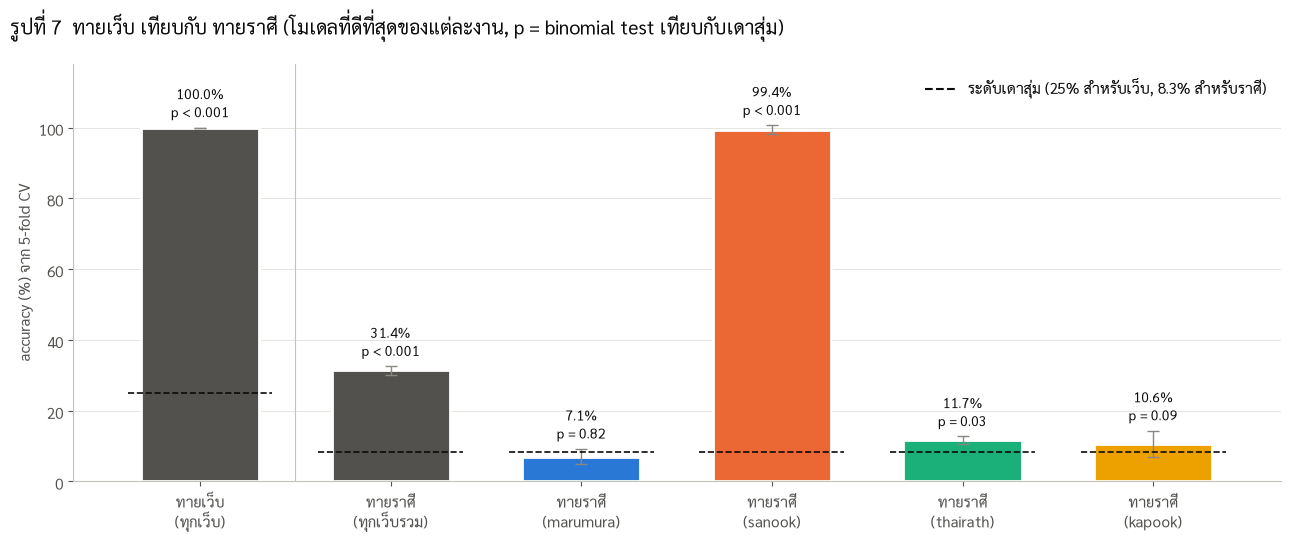

In [5]:
# Figure 7: accuracy of the best model per task, with the chance level of each task
fig, ax = plt.subplots(figsize=(13, 5.5))
labels = [t[0].replace(" (", "\n(") for t in TASKS]
colors = [NEUTRAL, NEUTRAL] + [SITE_COLORS[s] for s in SITES]
x = np.arange(len(TASKS))
ax.bar(x, best["accuracy"] * 100, width=0.62, color=colors, edgecolor="white", linewidth=2,
       yerr=best["acc_sd"] * 100, error_kw={"ecolor": "#898781", "capsize": 4, "linewidth": 1})
for k, (task, _, _, chance) in enumerate(TASKS):
    ax.hlines(chance * 100, k - 0.38, k + 0.38, colors="#0b0b0b", linestyles="--", linewidth=1.2)
    acc, p = best.loc[task, "accuracy"], best.loc[task, "p_vs_chance"]
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.2f}"
    ax.text(k, acc * 100 + best.loc[task, "acc_sd"] * 100 + 2, f"{acc:.1%}\n{p_text}",
            ha="center", va="bottom", fontsize=10)
ax.axvline(0.5, color="#c3c2b7", linewidth=0.8)
ax.set_xticks(x, labels)
ax.set_ylabel("accuracy (%) จาก 5-fold CV")
ax.set_ylim(0, 118)
ax.grid(axis="x", visible=False)
ax.plot([], [], color="#0b0b0b", linestyle="--", label="ระดับเดาสุ่ม (25% สำหรับเว็บ, 8.3% สำหรับราศี)")
ax.legend(frameon=False, loc="upper right")
fig.suptitle("รูปที่ 7  ทายเว็บ เทียบกับ ทายราศี (โมเดลที่ดีที่สุดของแต่ละงาน, p = binomial test เทียบกับเดาสุ่ม)",
             x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_accuracy_site_vs_sign.png")
plt.show()

**จากตารางและรูปที่ 7 พบว่า**
- **ทายเว็บได้ 100%** (chance 25%) ทุกโมเดลได้ 99.9–100% แต่ละเว็บมี "ลายมือ" ชัดเจนมาก
- **ทายราศีจากทุกเว็บรวมกันได้ 31.4%** (chance 8.3%) ดูเหมือนสูง แต่**เกือบทั้งหมดมาจาก sanook** (ดูรูปที่ 8)
- **ทายราศีภายในแต่ละเว็บ:**
  - **marumura 7.1%**: ต่ำกว่าระดับเดาด้วยซ้ำ (p = 0.82)
  - **kapook 10.6%**: ไม่ต่างจากระดับเดาอย่างมีนัยสำคัญ (p = 0.09)
  - **thairath 11.7%**: สูงกว่าระดับเดาเล็กน้อย (p = 0.03) แต่ผลนี้อ่อนมาก เพราะเราเลือกโมเดลที่ดีที่สุดจาก 3 โมเดล ซึ่งทำให้ p ดูดีกว่าความจริง และอีก 2 โมเดลได้แค่ 10.3% คือทายถูกเพิ่มจากการเดาประมาณ 1 ใน 30 ข้อความ
  - **sanook 99.4%**: แทบไม่ผิดเลย (ส่วนที่ 6 อธิบายว่าเพราะอะไร)

**ความหมาย:** 3 ใน 4 เว็บ โมเดลทายราศีได้**พอๆ กับการเดา** แต่ทายเว็บได้สมบูรณ์ แปลว่าข้อความต่างกันตาม**คนเขียน** ไม่ใช่ตาม**ราศี** ซึ่งตรงกับเงื่อนไข Barnum effect ที่ตั้งไว้ใน CLAUDE.md

## 3) แบ่ง 80:20 (stratified): classification report และ confusion matrix

ใช้ fold แรกของ `StratifiedGroupKFold(5)` เป็นการแบ่ง 80:20 (train 80%, test 20%) ที่ยังกันกลุ่มข้อความซ้ำไม่ให้รั่ว
โมเดลที่ใช้คือโมเดลที่ดีที่สุดจาก cross-validation ของแต่ละงาน

In [6]:
def split_80_20(data, target):
    train_idx, test_idx = next(CV.split(data, data[target], data["group"]))
    return data.iloc[train_idx], data.iloc[test_idx]

results_80_20 = {}
for task, site, target in [("ทายเว็บ (ทุกเว็บ)", None, "source"), ("ทายราศี (ทุกเว็บรวม)", None, "zodiac")]:
    train, test = split_80_20(df, target)
    model = make_model(MODELS[best.loc[task, "model"]]).fit(train["tokens"], train[target])
    pred = model.predict(test["tokens"])
    results_80_20[task] = (test[target].to_numpy(), pred)
    print(f"===== {task}  |  model: {best.loc[task, 'model']}  |  train {len(train)}, test {len(test)}")
    print(classification_report(test[target], pred, digits=3, zero_division=0))

===== ทายเว็บ (ทุกเว็บ)  |  model: Naive Bayes  |  train 986, test 247
              precision    recall  f1-score   support

      kapook      1.000     1.000     1.000        62
    marumura      1.000     1.000     1.000        63
      sanook      1.000     1.000     1.000        62
    thairath      1.000     1.000     1.000        60

    accuracy                          1.000       247
   macro avg      1.000     1.000     1.000       247
weighted avg      1.000     1.000     1.000       247



===== ทายราศี (ทุกเว็บรวม)  |  model: SVM (linear)  |  train 986, test 247
              precision    recall  f1-score   support

    Aquarius      0.455     0.476     0.465        21
       Aries      0.323     0.476     0.385        21
      Cancer      0.500     0.450     0.474        20
   Capricorn      0.214     0.150     0.176        20
      Gemini      0.267     0.200     0.229        20
         Leo      0.381     0.381     0.381        21
       Libra      0.312     0.238     0.270        21
      Pisces      0.412     0.350     0.378        20
 Sagittarius      0.259     0.350     0.298        20
     Scorpio      0.333     0.381     0.356        21
      Taurus      0.269     0.333     0.298        21
       Virgo      0.250     0.190     0.216        21

    accuracy                          0.332       247
   macro avg      0.331     0.331     0.327       247
weighted avg      0.331     0.332     0.327       247



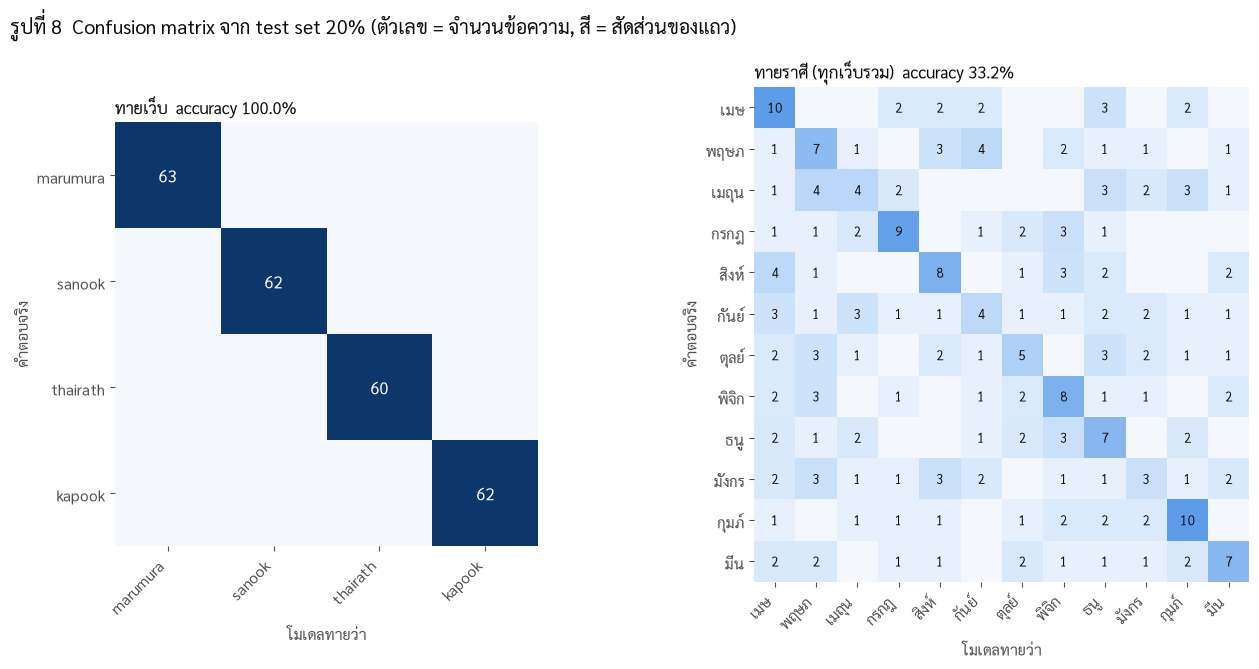

,test texts,correct,accuracy
site,,,
marumura,61,3,0.049
sanook,63,63,1.000
thairath,63,6,0.095
kapook,60,10,0.167


In [7]:
# Figure 8: confusion matrices (rows = true class, share of each row)
def draw_confusion(ax, y_true, y_pred, order, tick_labels, fontsize):
    cm = confusion_matrix(y_true, y_pred, labels=order)
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=BLUE_RAMP, vmin=0, vmax=1)
    ax.set_xticks(range(len(order)), tick_labels, rotation=45, ha="right")
    ax.set_yticks(range(len(order)), tick_labels)
    ax.set_xlabel("โมเดลทายว่า")
    ax.set_ylabel("คำตอบจริง")
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i in range(len(order)):
        for j in range(len(order)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=fontsize,
                        color="white" if share[i, j] > 0.5 else "#0b0b0b")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.8), gridspec_kw={"width_ratios": [4, 9]})
y_true, y_pred = results_80_20["ทายเว็บ (ทุกเว็บ)"]
draw_confusion(ax1, y_true, y_pred, SITES, SITES, fontsize=12)
ax1.set_title(f"ทายเว็บ  accuracy {np.mean(y_true == y_pred):.1%}", loc="left")
y_true, y_pred = results_80_20["ทายราศี (ทุกเว็บรวม)"]
draw_confusion(ax2, y_true, y_pred, SIGNS, [SIGN_TH[z] for z in SIGNS], fontsize=9)
ax2.set_title(f"ทายราศี (ทุกเว็บรวม)  accuracy {np.mean(y_true == y_pred):.1%}", loc="left")
fig.suptitle("รูปที่ 8  Confusion matrix จาก test set 20% (ตัวเลข = จำนวนข้อความ, สี = สัดส่วนของแถว)",
             x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_confusion_matrices.png")
plt.show()

# Where do the correct sign predictions come from? (test set, by site)
y_true, y_pred = results_80_20["ทายราศี (ทุกเว็บรวม)"]
_, test = split_80_20(df, "zodiac")
(pd.DataFrame({"site": test["source"].to_numpy(), "correct": y_true == y_pred})
   .groupby("site")["correct"].agg(["size", "sum", "mean"]).reindex(SITES)
   .rename(columns={"size": "test texts", "sum": "correct", "mean": "accuracy"}).round(3))

**จากรูปที่ 8 และตารางด้านบน พบว่า**
- **ทายเว็บ (ซ้าย):** ทายถูกทั้ง 247 ข้อความใน test set (precision = recall = F1 = 1.00 ทุกเว็บ)
- **ทายราศี (ขวา):** มีแนวทแยงจางๆ (ทายถูก 33.2%) แต่ส่วนใหญ่กระจายไปทั่ว ราศีเมษ ราศีกรกฎ และราศีกุมภ์ทายถูกมากที่สุด ส่วนราศีกันย์ ราศีมังกร และราศีเมถุนทายถูกน้อยที่สุด
- **แยกตามเว็บ:** ข้อความของ sanook ทายราศีถูก **63 จาก 63 (100%)** แต่อีก 3 เว็บถูกแค่ 3/61 (marumura), 6/63 (thairath) และ 10/60 (kapook)
  แปลว่า accuracy 33% ของการทายราศีแบบรวมทุกเว็บ**มาจาก sanook เกือบทั้งหมด** ถ้าดูแค่ 3 เว็บที่เหลือจะได้ 19/184 = 10.3% ใกล้ระดับเดา (8.3%)

**บทเรียนเรื่องการประเมินโมเดล:** ตัวเลข accuracy รวมตัวเดียว (33%) ทำให้เข้าใจผิดได้ ต้องแยกดูตามเว็บจึงจะเห็นภาพจริง

## 4) คำที่โมเดลใช้แยกเว็บ

ดูน้ำหนัก (coefficient) ของ Logistic Regression ที่เทรนกับข้อมูลทั้งหมด คำที่มีน้ำหนักสูงสุดของแต่ละเว็บคือ "ลายมือ" ของผู้เขียนเว็บนั้น

In [8]:
site_model = make_model(MODELS["Logistic Regression"]).fit(df["tokens"], df["source"])
vocab = site_model[0].get_feature_names_out()
coefs = site_model[-1].coef_
pd.DataFrame({site: vocab[np.argsort(coefs[k])[-12:][::-1]]
              for k, site in enumerate(site_model[-1].classes_)})[SITES]

,marumura,sanook,thairath,kapook
0,อย่า,ที่จะ,คู่,สถานการณ์
1,เอาเป็นว่า,วันที่,มีโอกาส,ความสัมพันธ์
2,ทำ,ควรระวัง,เกณฑ์,ปัญหา
3,รอ,ดาว,ดวง,เรื่องสำคัญ
4,ไม่ต้อง,อยู่ในเกณฑ์,ประสบความสำเร็จ,พิเศษ
5,เดี๋ยว,เขต,รายได้,ธุรกิจ
6,แล้วก็,สัมพันธ์,การงาน,คำเตือน
7,มีโชค,เป็นพิเศษ,การเงิน,เกิดขึ้น
8,แน่ๆ,บ่งบอก,เข้ามา,คำแนะนำ
9,โดน,โคจร,คน,ตัวเอง


**จากตาราง พบว่า** คำที่โมเดลใช้แยกเว็บคือ**สไตล์การเขียน**ของแต่ละเว็บ ไม่ได้เป็นเนื้อหาคำทำนาย
- **marumura:** ภาษาพูด เช่น "อย่า", "เอาเป็นว่า", "เดี๋ยว", "แล้วก็", "แน่ๆ", "โดน"
- **sanook:** ศัพท์โหราศาสตร์ เช่น "ดาว", "เขต", "โคจร", "สถิต", "สัญญาณ", "บ่งบอก", "อยู่ในเกณฑ์"
- **thairath:** "คู่" (คนมีคู่/คนโสด), "เกณฑ์", "ดวง", "ประสบความสำเร็จ", "ขอให้"
- **kapook:** หัวข้อประจำของเว็บ เช่น "สถานการณ์", "ความสัมพันธ์", "เรื่องสำคัญ", "คำเตือน", "คำแนะนำ"

จึงอธิบายได้ว่าทำไมทายเว็บได้ 100%: แต่ละเว็บมีคำติดปากและหัวข้อของตัวเอง

## 5) ตรวจความทนทานของผล: `text_strict` และตัดข้อความที่ลอกซ้ำ

ทำ cross-validation ซ้ำกับ (ก) `text_strict` (ตัด "คำแนะนำ" ของ sanook) และ (ข) `text_strict` ที่ตัดแถว `near_duplicate` ออกด้วย

In [9]:
variants = {
    "text": cv_main,
    "text_strict": cv_table(df, "tokens_strict"),
    "text_strict, ไม่มี near_duplicate": cv_table(df[~df["near_duplicate"]].reset_index(drop=True), "tokens_strict"),
}
robust = pd.DataFrame({
    name: tab.groupby("task")["accuracy"].max() for name, tab in variants.items()
}).reindex([t[0] for t in TASKS])
robust.insert(0, "chance", [t[3] for t in TASKS])
(robust * 100).round(1).astype(str) + "%"

,chance,text,text_strict,"text_strict, ไม่มี near_duplicate"
task,,,,
ทายเว็บ (ทุกเว็บ),25.0%,100.0%,100.0%,99.9%
ทายราศี (ทุกเว็บรวม),8.3%,31.4%,21.2%,21.3%
ทายราศี (marumura),8.3%,7.1%,7.1%,8.8%
ทายราศี (sanook),8.3%,99.4%,65.7%,70.8%
ทายราศี (thairath),8.3%,11.7%,11.7%,11.7%
ทายราศี (kapook),8.3%,10.6%,10.6%,10.6%


**จากตาราง robustness พบว่า**
- **ทายเว็บ:** ได้ 99.9–100% ทุกแบบ
- **thairath (11.7%) และ kapook (10.6%):** ไม่เปลี่ยนเลย
- **marumura:** ได้ 7.1% และ 8.8% เมื่อตัดข้อความที่ลอกซ้ำ ยังอยู่ที่ระดับเดา
- **sanook:** ลดจาก 99.4% เหลือ **65.7%** เมื่อตัดส่วน "คำแนะนำ" (`text_strict`) แต่ยังสูงกว่าระดับเดามาก ส่วนที่ 6 แสดงว่าส่วนที่ยังบอกราศีอยู่คือ "สุขภาพ"
- **ทุกเว็บรวม:** ลดจาก 31.4% เหลือประมาณ 21% ตาม sanook

ข้อสรุปหลักจึงไม่เปลี่ยนไม่ว่าจะเลือกข้อมูลแบบไหน คือ **ทายเว็บได้สมบูรณ์ แต่ทายราศีใน 3 เว็บได้แค่ระดับเดา**

## 6) sanook: ส่วนไหนของคำทำนายที่บอกราศี

sanook เป็นเว็บเดียวที่ทายราศีได้แม่น จึงแยกข้อความเป็น 5 ส่วนตามหัวข้อ (การเงิน, การงาน, ความรัก, สุขภาพ, คำแนะนำ)
แล้วทายราศีจาก**ทีละส่วน** พร้อมนับว่าแต่ละราศีมีข้อความของส่วนนั้นที่ไม่ซ้ำกันกี่แบบใน 26 สัปดาห์ (ถ้าน้อยกว่า 26 แปลว่ามีการใช้ซ้ำ)

In [10]:
import re

SECTION_HEADERS = {"การเงิน": "การเงิน", "การงาน": "การงาน", "ความรัก": "ความรัก", "สุขภาพ": "สุขภาพ"}
ADVICE_RE = re.compile(r"(?<=\s)คำแนะนำ(?=\s)")   # the stand-alone header, as in src/build_dataset.py

def split_sections(text):
    """Cut one sanook text into its sections, using the position of each header."""
    starts = {}
    for name, header in SECTION_HEADERS.items():
        m = re.search(r"(?:^|\s)" + header + r"(?=\s)", text)
        if m:
            starts[name] = m.start()
    m = ADVICE_RE.search(text, starts.get("สุขภาพ", 0))
    if m:
        starts["คำแนะนำ"] = m.start()
    ordered = sorted(starts.items(), key=lambda kv: kv[1])
    return {name: text[pos:(ordered[k + 1][1] if k + 1 < len(ordered) else len(text))]
            for k, (name, pos) in enumerate(ordered)}

san = df[df["source"] == "sanook"].reset_index(drop=True)
sections = san["text"].apply(split_sections)
rows = []
for name in list(SECTION_HEADERS) + ["คำแนะนำ"]:
    part = sections.apply(lambda s: s.get(name, ""))
    tokens = part.apply(lambda t: tokenize(clean_text(t)))
    acc = max(r["accuracy"] for r in run_cv(san.assign(part_tokens=tokens), "zodiac", "part_tokens"))
    rows.append({"ส่วน": name, "พบใน (แถว)": (part != "").sum(), "ความยาวเฉลี่ย (ตัวอักษร)": part.str.len().mean(),
                 "แบบที่ไม่ซ้ำต่อราศี (จาก ~26)": san.assign(p=part).groupby("zodiac")["p"].nunique().mean(),
                 "accuracy ทายราศี": acc})
section_table = pd.DataFrame(rows)
section_table.round(3)

,ส่วน,พบใน (แถว),ความยาวเฉลี่ย (ตัวอักษร),แบบที่ไม่ซ้ำต่อราศี (จาก ~26),accuracy ทายราศี
0,การเงิน,309,218.689,25.750,0.159
1,การงาน,308,300.107,25.750,0.104
2,ความรัก,308,355.845,25.750,0.275
3,สุขภาพ,268,148.932,14.250,0.747
4,คำแนะนำ,309,599.544,13.917,0.987


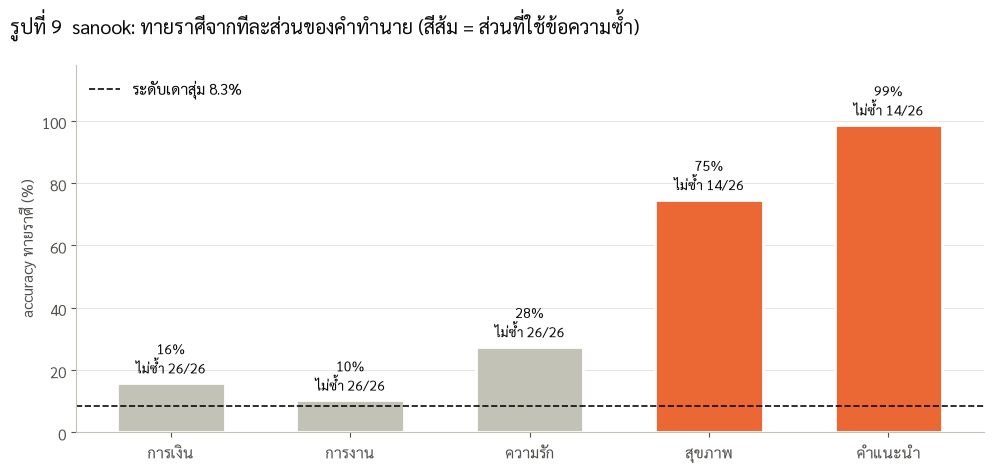

In [11]:
# Figure 9: sign accuracy from each sanook section alone
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(section_table))
reused = section_table["แบบที่ไม่ซ้ำต่อราศี (จาก ~26)"] < 20
ax.bar(x, section_table["accuracy ทายราศี"] * 100, width=0.6, edgecolor="white", linewidth=2,
       color=[SITE_COLORS["sanook"] if r else "#c3c2b7" for r in reused])
ax.axhline(100 / 12, color="#0b0b0b", linestyle="--", linewidth=1.2, label="ระดับเดาสุ่ม 8.3%")
for k, row in section_table.iterrows():
    ax.text(k, row["accuracy ทายราศี"] * 100 + 2,
            f"{row['accuracy ทายราศี']:.0%}\nไม่ซ้ำ {row['แบบที่ไม่ซ้ำต่อราศี (จาก ~26)']:.0f}/26",
            ha="center", va="bottom", fontsize=10)
ax.set_xticks(x, section_table["ส่วน"])
ax.set_ylabel("accuracy ทายราศี (%)")
ax.set_ylim(0, 118)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left")
fig.suptitle("รูปที่ 9  sanook: ทายราศีจากทีละส่วนของคำทำนาย (สีส้ม = ส่วนที่ใช้ข้อความซ้ำ)",
             x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_sanook_sections.png")
plt.show()

**จากรูปที่ 9 พบว่า** ในเว็บ sanook มีแค่ 2 ส่วนที่บอกราศี และทั้ง 2 ส่วนเป็นส่วนที่**ใช้ข้อความซ้ำ**
- **"คำแนะนำ" ทายถูก 99%** และ **"สุขภาพ" ทายถูก 75%**: แต่ละราศีมีข้อความไม่ซ้ำกันแค่ประมาณ **14 แบบจาก 26 สัปดาห์** คือนำย่อหน้าเดิมเกี่ยวกับดาวประจำราศีและโรคประจำราศีมาใช้หลายสัปดาห์ (เช่น ราศีเมษได้ "ปวดศีรษะ ไมเกรน" ซ้ำๆ)
- **ส่วนคำทำนายที่เขียนใหม่ทุกสัปดาห์** (ไม่ซ้ำ 26/26): "การเงิน" 16%, "การงาน" 10% และ "ความรัก" 28% ใกล้ระดับเดาเหมือนเว็บอื่น (ยกเว้นความรักที่สูงกว่าเล็กน้อย)

**ความหมาย:** sanook ไม่ได้เขียนคำทำนาย**รายสัปดาห์**ที่ต่างกันตามราศี แต่มี**ย่อหน้าประจำราศี**ที่นำมาใช้ซ้ำ ซึ่งเป็นคำบรรยายลักษณะราศีตามหลักโหราศาสตร์ ไม่ได้ทำนายว่าสัปดาห์นั้นจะเกิดอะไรขึ้น
เมื่อดูเฉพาะส่วนที่ทำนายรายสัปดาห์ ผลจึงเหมือนอีก 3 เว็บ

## สรุปผล 03 Classification (ตอบวัตถุประสงค์ข้อ 1 ส่วนที่สอง)

| งาน | chance | accuracy (5-fold CV) |
|---|---|---|
| ทาย**เว็บ** | 25% | **100%** |
| ทาย**ราศี** ภายใน marumura / thairath / kapook | 8.3% | **7.1% / 11.7% / 10.6%** (ระดับเดา) |
| ทาย**ราศี** ภายใน sanook | 8.3% | 99.4% (65.7% เมื่อตัดคำแนะนำ) |
| ทาย**ราศี** ภายใน sanook เฉพาะส่วนที่เขียนใหม่ทุกสัปดาห์ (การเงิน/การงาน) | 8.3% | 10–16% |

1. **ทายเว็บได้สมบูรณ์ ทายราศีได้แค่ระดับเดา** ใน 3 จาก 4 เว็บ ซึ่งเข้าเงื่อนไข **Barnum effect** ที่ตั้งไว้: ความต่างของข้อความมาจากคนเขียน ไม่ได้มาจากราศี
2. **sanook เป็นข้อยกเว้นที่มีคำอธิบาย:** ทายราศีได้เพราะมีย่อหน้า "คำแนะนำ" และ "สุขภาพ" ประจำราศีที่ใช้ซ้ำ ส่วนคำทำนายรายสัปดาห์ (เงิน งาน) ทายได้แค่ระดับเดาเหมือนเว็บอื่น
3. **ตัวเลขรวมหลอกตาได้:** ทายราศีแบบรวมทุกเว็บได้ 31% ดูเหมือนสูง แต่เกือบทั้งหมดมาจาก sanook
4. **ผลไม่เปลี่ยน** เมื่อใช้ `text_strict` หรือตัดข้อความที่ลอกซ้ำ และสอดคล้องกับโน้ตบุ๊ก 02 (similarity)

**ข้อจำกัด:** แต่ละเว็บมีข้อมูลแค่ประมาณ 26 ข้อความต่อราศี ซึ่งอาจน้อยเกินไปที่จะจับความต่างเล็กๆ ได้ และเราใช้แค่ TF-IDF ของคำ (bag of words) ซึ่งไม่ได้ดูลำดับหรือความหมายของประโยค

**รูปที่บันทึกไว้:** `outputs/figures/03_accuracy_site_vs_sign.png`, `03_confusion_matrices.png`, `03_sanook_sections.png`